# Caribu: light in plant canopies, in metafspm

Caribu (`openalea.caribu`) computes the light that each triangle of a canopy receives and absorbs. This package is
its port to Python (numpy, numba), without its C++ executables or files, and a metafspm component built on it:
- **direct light**: each source projected on a z-buffer, the canopy infinite when a pattern repeats it;
- **radiosity**: every order of scattering between the triangles of a closed scene;
- **nested radiosity**: in an infinite canopy, radiosity between the triangles within a sphere, and a turbid medium
  of layers beyond it (mcsail: SAIL with several layers); with a null sphere, pure SAIL;
- **light sources**: turtle skies, sector skies (standard or uniform overcast), the sun's position, the diffuse
  fraction of global radiation;
- **`CaribuLight`**: a metafspm `FunctionalComponent`, which lights the elements of one or several plant
  populations from their triangles.

The previous package is kept in `openalea.caribu.legacy`. It drives libcaribu's executables, and the port is
compared with it in the tests. By default (`precision="legacy"`) every output equals the legacy's, digit for digit.
`corrections="recommended"` corrects its behaviours, each tested by the physics it restores. The component uses the
corrections by default.

The steps:
0. reading the code: metafspm's component formalism, on `CaribuLight`;
1. the light models on a canopy's triangles;
2. the light sources;
3. the infinite canopy and the corrections;
4. lighting a canopy again: the `Canopy`;
5. `CaribuLight` in a metafspm scene, on a stand grown by Adel's port;
6. the comparison with the legacy, and the speed.

Lengths are in m, irradiances in the light sources' unit (here relative: a sky of unit energy).

In [1]:
import inspect
import time

import matplotlib.pyplot as plt
import numpy as np

from openalea.caribu import corrections, direct, formats, lights, nested, radiosity
from openalea.caribu.canopy import Canopy
from openalea.caribu.component import CaribuLight, CaribuLightModel
from openalea.caribu.labels import encode_labels
from openalea.caribu.legacy.data_samples import data_path

## 0. Reading the code: metafspm's component formalism

`CaribuLight` is a metafspm `FunctionalComponent`. All the ported models are written in the same form; this section
presents it on `CaribuLight`, so that its code (`openalea.caribu.component`) can be read. For more, metafspm's
tutorial `examples/soil_plant_atmosphere/tutorial_fspm2026_general_usage.ipynb` (in the metafspm repository) builds
components step by step; its user guide `docs/user.md` describes each part.

- **A component is a dataclass.** Its fields declare its variables:
  - `input_variable`: written by another model (`by`), read here;
  - `state_variable`: computed by this component;
  - `parameter`: a constant, which may differ between plants.

  Each declaration documents its variable (`unit`, `description`) and places it at a **scale** of the plant graph:
  `CaribuLight`'s are at the elements' scale, `SubOrgan`.
- **Its processes are steps:** methods decorated by their place in the schedule (`@rate`, `@state`, ...). A step's
  arguments are variables, named as declared. Each comes as a whole array, one value per element, for every plant
  at once. A step returns its output, named after the method, or several outputs as a dict `{name: values}`.
- **Forcings are declared too** (`forcing_variable`): time series given from outside the scene (a meteo table),
  the same for every entity, read by `self.forcing(name)` at the step's time; unlike an input, written per entity by
  another model through the translator. A scene checks at its construction that the required ones are given.
- **The values live in the DataStructure**, one array per variable: `ds.get(name)`, `ds.set(name, values)`. The plant
  graph (an MTG, metafspm's MPG) holds the topology and the labels, read through `ds.structure`.
- **An environment model lights the plants.** A metafspm `Scene` builds each population of plants and gives the
  environment models their DataStructures: `CaribuLightModel(populations, scene_xrange, scene_yrange, time_step)`
  builds `CaribuLight` on the population's DataStructure, or on a `UnionDataStructure` of several populations.
- **The geometry comes from the structural component.** A `StructuralComponent` (Adel's `ShootArchitecture`, a root
  model's segments) registers itself on its DataStructure, and `ds.triangles()` returns the elements' triangles with
  each one's node index. `CaribuLight` reads them at each lighting, and gives its results back per element.

`CaribuLight.declarations()` lists what the component declares: its inputs (an optical model's optics), its
forcings (the incident PAR, and the diffuse fraction when the sun is on), its state variables:

In [2]:
declarations = CaribuLight.declarations()
print(declarations["kind"].value_counts().to_string())
declarations.loc[declarations["kind"] != "parameter", ["name", "kind", "scale", "unit", "description"]]

kind
state_variable    7
parameter         6
input             2
forcing           2


,name,kind,scale,unit,description
0,PAR_reflectance,input,SubOrgan,adim,"The element's reflectance in the PAR, from an ..."
1,PAR_transmittance,input,SubOrgan,adim,"The element's transmittance in the PAR, from a..."
2,PARi,forcing,time series,µmol m-2 s-1,"The PAR above the canopy, on a horizontal plane"
3,diffuse_fraction,forcing,time series,adim,"The diffuse share of the incident radiation, w..."
4,reflectance,state_variable,SubOrgan,adim,The element's reflectance in the light model
5,transmittance,state_variable,SubOrgan,adim,The element's transmittance in the light model...
6,Erel,state_variable,SubOrgan,adim,"The PAR the element absorbs per unit area, rel..."
7,Erel_incident,state_variable,SubOrgan,adim,The PAR reaching the element per unit area (it...
8,lit_area,state_variable,SubOrgan,m2,The element's area in the light model (its tri...
9,PARa,state_variable,SubOrgan,µmol m-2 s-1,The PAR the element absorbs per unit area


Its parameters are the plants': the optics of the leaf and stem elements (Wheat-BRIDGES' values by default), which
may differ from one plant to another (a genotype's leaves), and the MTG labels telling leaves from stems. How the
canopy is lit is the same for all the plants: one `Lighting`, its last parameter.

In [3]:
declarations.loc[declarations["kind"] == "parameter", ["name", "default", "unit", "description"]]

,name,default,unit,description
11,leaf_reflectance,0.1,adim,A leaf element's reflectance in the PAR
12,leaf_transmittance,0.05,adim,A leaf element's transmittance in the PAR
13,stem_reflectance,0.1,adim,A stem element's reflectance in the PAR (opaque)
14,leaf_labels,"(LeafElement, LeafElement1)",,The MTG labels of the leaf elements (two faces...
15,stem_labels,"(StemElement,)",,The MTG labels of the stem elements (opaque)
16,lighting,"Lighting(mode='direct', infinite=True, sphere_...",,"How the canopy is lit: the light model, the sk..."


A `Lighting` gathers the light model, the sky and the sun, the site, the soil and the numerics. Its defaults
reproduce Wheat-BRIDGES' use of Caribu: direct light in an infinite canopy under a standard overcast sky of 4 × 5
sectors, lit every 4 hours; with the corrections and the computed values (precision "full").

In [4]:
import dataclasses

from openalea.caribu.component import Lighting

for field in dataclasses.fields(Lighting):
    print(f"{field.name:>18} = {field.default!r}")

              mode = 'direct'
          infinite = True
   sphere_diameter = 0.5
            layers = 10
               sky = 'sectors'
          sky_type = 'soc'
   azimuth_sectors = 4
    zenith_sectors = 5
               sun = False
   global_per_PARi = 0.45587162654996355
          latitude = 48.85
       orientation = 0.0
 start_day_of_year = 1.0
        start_hour = 0.0
        soil_level = 0.0
  soil_reflectance = 0.15
 lighting_interval = 14400.0
       screen_size = 1536
         precision = 'full'
       corrections = 'recommended'
            device = 'cpu'
     linear_solver = 'mgcr'


Its three steps follow the physics: `_optics` gives each element its reflectance and transmittance (an optical
model's inputs, else its kind's), `_relative_light` lights the canopy (`ds.triangles()` above the soil) under a sky
of unit energy, `_absorbed_PAR` scales the relative light by the incident PAR, the forcing `PARi`.
`CaribuLightModel` lights the canopy every `lighting_interval` (and when elements appear); at the other steps it
runs only the row "state", `_absorbed_PAR`: PARa follows PARi with the last Erel.

In [5]:
for stages, steps in CaribuLight.schedule():
    print(f"{', '.join(stages):>10}  {', '.join(steps)}")
for step in (CaribuLight._optics, CaribuLight._relative_light, CaribuLight._absorbed_PAR):
    print(inspect.getsource(step))

      rate  _optics, _relative_light
     state  _absorbed_PAR
    @rate(include_inactive=True)
    def _optics(self, PAR_reflectance, PAR_transmittance, leaf_reflectance, leaf_transmittance,
                stem_reflectance) -> dict:
        """Each element's optics: an optical model's, else its kind's (a leaf ρ, τ; a stem ρ, opaque); NaN for an
        element of another kind."""
        leaf, stem = self.element_kinds()
        given = ~np.isnan(PAR_reflectance)
        reflectance = np.where(given, PAR_reflectance,
                               np.where(leaf, leaf_reflectance, np.where(stem, stem_reflectance, np.nan)))
        transmittance = np.where(given, PAR_transmittance, np.where(leaf, leaf_transmittance, np.nan))
        return {"reflectance": reflectance, "transmittance": transmittance}

    @rate(include_inactive=True)
    def _relative_light(self, reflectance, transmittance) -> dict:
        """The canopy lit by a sky of unit energy: each element's absorbed and incident 

## 1. The light models on a canopy's triangles

Under the component, the models work on arrays:
- **vertices** `(n, 3, 3)`: the triangles;
- **labels** `(n,)`: each triangle's optical species, and whether it is a leaf (two faces, translucent) or opaque (a
  stem, one face). `encode_labels(species, leaf=...)` writes them;
- **optics**: `(soil reflectance, {species: (ρ stem, ρ upper, τ upper, ρ lower, τ lower)})`;
- **lights**: `[(E, (vx, vy, vz))]`, E the irradiance on a horizontal plane and (vx, vy, vz) the beam's direction;
- a **pattern** `(xmin, ymin, xmax, ymax)` for an infinite canopy, repeated in x and y.

The canopy here is the legacy's 100-plant Adel scene (34,647 triangles, in m), its pattern the scene's extent,
under the 46-direction turtle sky:

In [6]:
vertices, labels = formats.read_can_arrays(data_path("f331s1_100plantes.can"))
flat = vertices.reshape(-1, 3)
pattern = (float(flat[:, 0].min()), float(flat[:, 1].min()), float(flat[:, 0].max()), float(flat[:, 1].max()))
ground = (pattern[2] - pattern[0]) * (pattern[3] - pattern[1])
height = float(flat[:, 2].max())
labels = encode_labels(1, leaf=1, plant=(labels // 10 ** 6) % 10 ** 5)   # one species of leaves
optics = (0.15, {1: (0.10, 0.10, 0.05, 0.10, 0.05)})
sky = lights.turtle_lights("46", "soc", energy=1.)
print(f"{len(vertices)} triangles, pattern {np.round(pattern, 3)}, {len(sky)} sources")

34644 triangles, pattern [-2.936 -3.499  0.526  0.505], 46 sources


The models, with the corrections (and `precision="full"`, the values as computed):
- `direct.run`: the first order only;
- `nested.run(..., diameter=0)`: pure SAIL, the first order plus the turbid medium's scattered light;
- `nested.run(..., diameter=D)`: nested radiosity, radiosity within a sphere of diameter D.

Each returns, per triangle, its `area`, the irradiance `Ei` (both faces), the absorbed `Eabs`, both per unit area:

In [7]:
recommended = corrections.resolve("recommended")


def absorbed(result):
    """The canopy's absorbed light per m² of ground."""
    return float(np.nansum(np.asarray(result["Eabs"], dtype=float) * result["area"])) / ground


direct.run(vertices[:300], labels[:300], sky[:2], optics, pattern=pattern)     # numba compiles at the first calls
nested.run(vertices[:300], labels[:300], sky[:2], optics, pattern, 3, height, 0.5)
models = {"direct": lambda: direct.run(vertices, labels, sky, optics, pattern=pattern, corrections=recommended),
          "pure SAIL": lambda: nested.run(vertices, labels, sky, optics, pattern, 10, height, 0., precision="full",
                                          corrections=recommended),
          "nested D = 0.25 m": lambda: nested.run(vertices, labels, sky, optics, pattern, 10, height, 0.25,
                                                  precision="full", corrections=recommended),
          "nested D = 0.5 m": lambda: nested.run(vertices, labels, sky, optics, pattern, 10, height, 0.5,
                                                 precision="full", corrections=recommended)}
results = {}
for name, run in models.items():
    started = time.perf_counter()
    results[name] = run()
    print(f"{name:>18}: absorbed {absorbed(results[name]):.3f} per m² of ground, in {time.perf_counter() - started:.2f} s")

            direct: absorbed 0.610 per m² of ground, in 0.69 s


         pure SAIL: absorbed 0.704 per m² of ground, in 0.95 s


 nested D = 0.25 m: absorbed 0.697 per m² of ground, in 2.29 s


  nested D = 0.5 m: absorbed 0.697 per m² of ground, in 3.43 s


Scattering adds light: the canopy absorbs more with the turbid medium's scattered light than with direct light only.
Down the canopy, the light each leaf absorbs falls as the leaf area above it grows:

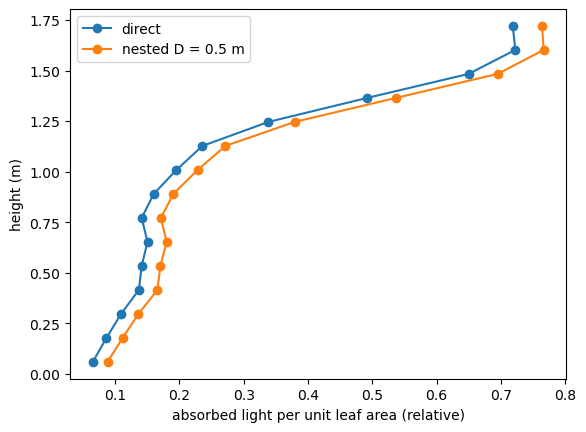

In [8]:
centres = vertices.mean(axis=1)
bins = np.linspace(0, height, 16)
layer = np.digitize(centres[:, 2], bins)
for name in ("direct", "nested D = 0.5 m"):
    result = results[name]
    eabs, area = np.nan_to_num(np.asarray(result["Eabs"], dtype=float)), np.asarray(result["area"])
    mean = [np.sum((eabs * area)[layer == k]) / max(np.sum(area[layer == k]), 1e-12) for k in range(1, len(bins))]
    plt.plot(mean, bins[1:] - (bins[1] - bins[0]) / 2, "o-", label=name)
plt.xlabel("absorbed light per unit leaf area (relative)")
plt.ylabel("height (m)")
plt.legend();

Radiosity in a closed scene (`radiosity.run`) computes every exchange between the triangles: the full scene's
1.26 M pairs take about a minute. Here the first 3,000 triangles:

In [9]:
started = time.perf_counter()
closed = radiosity.run(vertices[:3000], labels[:3000], sky, optics, corrections=recommended)
first_order = direct.run(vertices[:3000], labels[:3000], sky, optics, corrections=recommended)
print(f"radiosity on 3,000 triangles in {time.perf_counter() - started:.1f} s ({closed['steps']} solver steps); "
      f"scattering adds {np.nansum(closed['Eabs'] * closed['area']) / np.nansum(first_order['Eabs'] * first_order['area']) - 1:.1%} "
      f"to the absorbed light")

radiosity on 3,000 triangles in 1.1 s (5 solver steps); scattering adds 7.8% to the absorbed light


## 2. The light sources

`lights` builds the sources:
- `turtle_lights("46" or "16", "soc" or "uoc", energy)`: the turtle's directions;
- `Sky(azimuths, zeniths).diffuse(energy, "soc")`: sectors of a standard (soc) or uniform (uoc) overcast sky,
  `.place_sun(sun)` or `.add_sun(sun)`, `.lights()`;
- `sun_light(energy, day_of_year, hour, latitude)`, `Sun().place(...)`: the sun;
- `diffuse_fraction(global_radiation, day_of_year, hour, latitude)`: Spitters' diffuse fraction;
- `hourly_global_radiation(daily, hour, day_of_year, latitude)`: the hours of a day's global radiation.

With `corrections="recommended"`, the azimuths are counted from North, clockwise, X+ at `orientation` degrees from
North. A clear May day at Paris (28 MJ m-2 of global radiation):

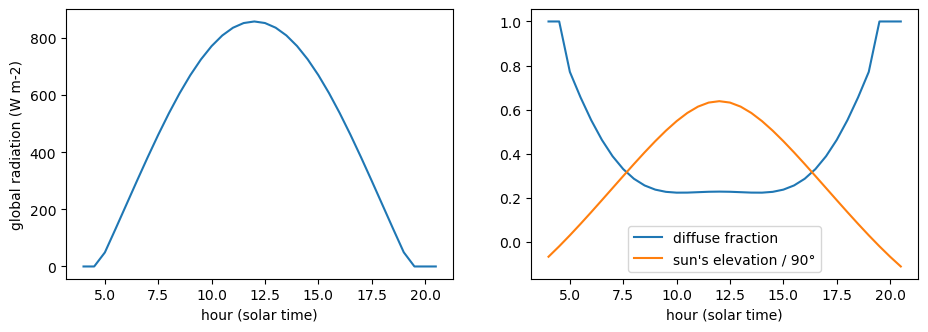

In [10]:
hours = np.arange(4., 21., 0.5)
global_radiation = [max(lights.hourly_global_radiation(28e6, hour, 126, 48.85), 0.) for hour in hours]
fraction = [lights.diffuse_fraction(value, 126, hour, 48.85) if value > 0 else 1. for value, hour in zip(global_radiation, hours)]
elevation = [90 - np.degrees(lights.Sun(corrections="recommended").place(126, hour, np.radians(48.85)).zenith) for hour in hours]
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(hours, global_radiation)
axes[0].set_ylabel("global radiation (W m-2)")
axes[1].plot(hours, fraction, label="diffuse fraction")
axes[1].plot(hours, np.array(elevation) / 90, label="sun's elevation / 90°")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("hour (solar time)")

## 3. The infinite canopy and the corrections

In an infinite canopy the pattern repeats the scene. A triangle across the pattern's border belongs to both sides:
its part beyond the border is the neighbouring pattern's. canestrad copies such a triangle only towards +x and +y,
and its screen does not always reach the part beyond. A lone leaf across the border then receives less than the
light on the ground:

In [11]:
def square(x, y, side, z=0.5):
    a, b, c, d = (x, y, z), (x + side, y, z), (x + side, y + side, z), (x, y + side, z)
    return np.array([[a, b, c], [a, c, d]])


leaf_label, unit_pattern = encode_labels(1, leaf=1), (0., 0., 1., 1.)
print("leaf corner   legacy   corrected   (Ei, the incident light per unit area; the ground receives 1)")
for x, y in ((0.3, 0.3), (0.8, 0.4), (0.8, 0.8), (-0.1, -0.1)):
    row = []
    for chosen in ((), recommended):
        result = direct.run(square(x, y, 0.3), leaf_label, sky, optics, pattern=unit_pattern, corrections=chosen)
        row.append(np.sum(result["Ei"] * result["area"]) / np.sum(result["area"]))
    print(f"({x:4.1f}, {y:4.1f})   {row[0]:6.3f}   {row[1]:9.3f}")

leaf corner   legacy   corrected   (Ei, the incident light per unit area; the ground receives 1)


( 0.3,  0.3)    0.999       1.000


( 0.8,  0.4)    0.927       1.000


( 0.8,  0.8)    0.685       1.001


(-0.1, -0.1)    0.780       1.000


The corrections (`openalea.caribu.corrections`), each tested in `test/test_corrections.py`:

In [12]:
for name, description in corrections.NAMES.items():
    print(f"{name:>22}  {description}")

         border_copies  a triangle across the pattern's borders copied on each side it crosses, corners included
                tiling  the neighbouring patterns' images placed by the lattice's exact vectors, each translate rounded on its own, its depth offset exact
         sensor_copies  sensors copied across the borders as triangles, each copy's pixels counted once
            pixel_area  a pixel's area the pitch's, du dv / (T - 1)^2
          upward_beams  a source whose beam goes up or along the ground lights nothing
             periodise  the periodised scene in float32 without its text rounding, lifted to exactly z >= 0
         triangle_area  a triangle's area 0.5 |AB x AC|
           voxel_floor  the receiver's voxel floor((G - O) / side)
           face_counts  an emitter's two faces counted apart
        projected_face  each pixel's emitter face the one of the copy projected there
 profile_interpolation  the far field's levels interpolated with weights (1 - f, f)
        p

Two of them make the results independent of the scene's unit. canestrad finds a receiver's neighbours from its
voxel, `int(trunc(G − O) / side)`: in metres, with a sphere below 1 m, most near neighbours are searched around the
wrong voxel and left to the far field. And it tiles the neighbouring patterns by steps rounded to pixels, repeated:
the k-th neighbour lies up to k pixels off. The same canopy in m and in cm:

In [13]:
random = np.random.default_rng(3)
leaf_centres = np.c_[random.uniform(0, 0.4, (300, 2)), random.uniform(0.05, 0.6, 300)]
small = np.array([[c, c + random.normal(0, 0.03, 3), c + random.normal(0, 0.03, 3)] for c in leaf_centres])
sky16 = lights.turtle_lights("16", "soc", 1.)
for name, chosen in (("legacy", frozenset()), ("corrected", recommended)):
    runs = [nested.run(small * scale, leaf_label, sky16, optics, (0, 0, 0.4 * scale, 0.4 * scale), 5, 0.65 * scale,
                       0.1 * scale, precision="full", corrections=chosen, size=512) for scale in (1., 100.)]
    pairs = [len(run["counts"][1]) for run in runs]
    difference = np.abs(np.asarray(runs[0]["Eabs"], float) - np.asarray(runs[1]["Eabs"], float))
    print(f"{name:>9}: near-field pairs in m {pairs[0]}, in cm {pairs[1]}; Eabs m vs cm, mean |difference| {difference.mean():.1e}")

   legacy: near-field pairs in m 59, in cm 435; Eabs m vs cm, mean |difference| 3.6e-03


corrected: near-field pairs in m 610, in cm 609; Eabs m vs cm, mean |difference| 1.3e-04


## 4. Lighting a canopy again: the `Canopy`

A `Canopy` keeps what depends only on the geometry: the scene as canestrad reads it, each direction's lit areas,
the near field's form factors. A second band, other optics or a new hour then cost little:

In [14]:
canopy = Canopy(vertices, labels, pattern=pattern, corrections="recommended")
for name, band_optics in (("PAR", optics), ("NIR", (0.2, {1: (0.4, 0.45, 0.45, 0.45, 0.45)}))):
    started = time.perf_counter()
    result = canopy.direct(sky, band_optics)
    print(f"{name}: absorbed {absorbed(result):.3f}, in {time.perf_counter() - started:.2f} s")

PAR: absorbed 0.610, in 0.68 s
NIR: absorbed 0.072, in 0.20 s


`example/day_course.py` lights the canopy hour by hour, the sky's directions projected once.

## 5. `CaribuLight` in a metafspm scene

A stand of 20 wheat plants grown by Adel's port (`openalea.adel`, its `ShootArchitecture` drawing the elements),
sown as Adel's examples (echap's leaf shapes by age class, each plant at its coleoptile's sowing depth), lit by
`CaribuLightModel`. The parts of the elements below the soil (`soil_level`, 0 by default), the sown stems' bases,
are left out of the light model: the soil is opaque. Each scene step is an hour and 10 °Cd. The scene's forcing `PARi` is the incident PAR of
clear May days (µmol m-2 s-1). `CaribuLight` lights the canopy every 4 hours, under the sky and the sun, the diffuse
fraction Spitters' (from PARi). In between, each element's PARa follows PARi with its last Erel:

96 hours in 23.4 s, 18454 triangles at the end


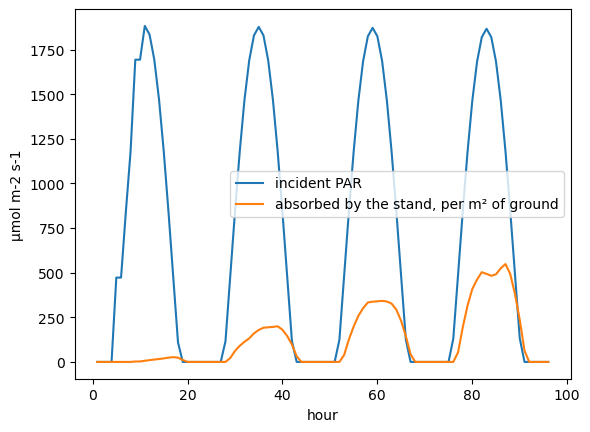

In [15]:
import sys
sys.path.insert(0, "..")                                   # example/canopy_light.py
from canopy_light import XRANGE, YRANGE, incident_PAR, stand_scene

scene = stand_scene()
ds = scene.populations[0].data_structure
light = scene.environment[0].light
hours, incident, stand_absorbed = [], [], []
started = time.perf_counter()
for step in range(96):
    scene.run()
    hours.append(scene.time / 3600.)
    incident.append(light.forcing("PARi"))
    stand_absorbed.append(float(np.sum(np.asarray(ds.get("PARa")) * np.asarray(ds.get("lit_area")))) / (XRANGE * YRANGE))
print(f"96 hours in {time.perf_counter() - started:.1f} s, {len(ds.triangles())} triangles at the end")
plt.plot(hours, incident, label="incident PAR")
plt.plot(hours, stand_absorbed, label="absorbed by the stand, per m² of ground")
plt.xlabel("hour")
plt.ylabel("µmol m-2 s-1")
plt.legend();

The stand, and each element's `Erel` (absorbed per unit area, relative to the incident PAR), drawn with metafspm's
`display`:

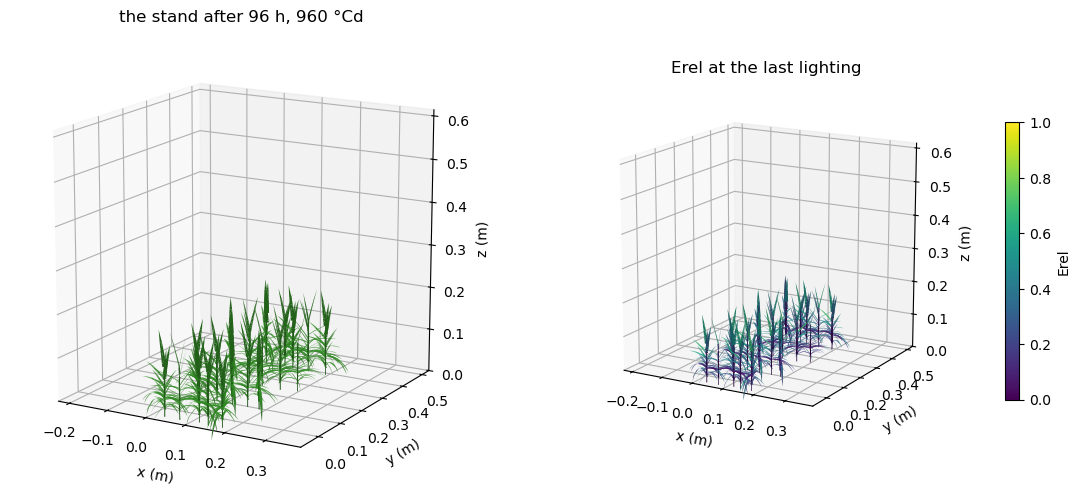

In [16]:
from openalea.metafspm.display import draw, value_colors

figure = plt.figure(figsize=(14, 6))
axes = figure.add_subplot(1, 2, 1, projection="3d")
draw(axes, ds.triangles())
axes.set_title("the stand after 96 h, 960 °Cd")
axes = figure.add_subplot(1, 2, 2, projection="3d")
draw(axes, ds.triangles(), colors=value_colors(np.asarray(ds.get("Erel")), limits=(0., 1.)))
figure.colorbar(plt.cm.ScalarMappable(cmap="viridis"), ax=axes, shrink=0.6, pad=0.12, label="Erel")
axes.set_title("Erel at the last lighting");

Several populations (an intercrop, two genotypes) share the light: `CaribuLightModel` then runs on a
`UnionDataStructure` of their DataStructures, and the scene's translator gives each population its outputs, e.g.
`translator.link("WheatPhotosynthesis", "PARa", "CaribuLight", {"PARa": 1.})` (`test/test_component.py`).

A coupled model can give each element its optics, through the inputs `PAR_reflectance` and `PAR_transmittance`; a
NaN transmittance makes it opaque. The other elements take their kind's: the plant parameters `leaf_reflectance`,
`leaf_transmittance` and `stem_reflectance`, which may differ from one plant to another, by their MTG labels
(`leaf_labels`, `stem_labels`).

## 6. Precision, corrections and speed

**Precision.** With `precision="legacy"` and no corrections, every output equals the legacy's to its printed
digits: canestrad's, s2v's and mcsail's files, the API's dicts (`test/comparison`); the legacy's own tests run on
the port. `CaribuLight` with `Lighting(precision="legacy", corrections=())` reproduces Wheat-BRIDGES' Erel exactly
(`test/test_component_adel.py`). `precision="full"` keeps the computed values: it differs from the legacy's by its
rounding (in metres, the 6-decimal areas of small triangles move an element's Erel by up to 0.0125).

**Speed.** The time of each model on the Adel scene (34,644 triangles, 46 sources; a laptop), the legacy's when
libcaribu is installed:

In [17]:
from openalea.caribu.comparison import legacy_run, port_run

materials = {1: (0.10, 0.05)}
legacy_optics = port_run.optics(materials, 0.15)
cases = (("direct", lambda: direct.run(vertices, labels, sky, legacy_optics, pattern=pattern),
          lambda: legacy_run.direct(vertices, labels, sky, materials, 0.15, pattern=pattern)),
         ("pure SAIL", lambda: nested.run(vertices, labels, sky, legacy_optics, pattern, 10, height, 0),
          lambda: legacy_run.layered(vertices, labels, sky, materials, pattern, 10, height, 0.15)),
         ("nested D = 0.5 m", lambda: nested.run(vertices, labels, sky, legacy_optics, pattern, 10, height, 0.5),
          lambda: legacy_run.layered(vertices, labels, sky, materials, pattern, 10, height, 0.15, diameter=0.5)))
for name, port, legacy in cases:
    started = time.perf_counter()
    port()
    port_time = time.perf_counter() - started
    legacy_time = None
    if legacy_run.available():
        started = time.perf_counter()
        legacy()
        legacy_time = time.perf_counter() - started
    print(f"{name:>17}: port {port_time:5.2f} s" + (f", legacy {legacy_time:5.2f} s" if legacy_time else ""))

           direct: port  0.66 s, legacy  3.65 s


        pure SAIL: port  0.75 s, legacy  3.80 s


 nested D = 0.5 m: port  2.54 s, legacy 12.92 s


**The corrections do not make the models faster**; one makes nested radiosity slower. canestrad's receiver voxel
misses near neighbours in a metre scene: with `voxel_floor` the near field finds them, and computes more form
factors:

In [18]:
for name, chosen in (("legacy", frozenset()), ("corrected", recommended)):
    started = time.perf_counter()
    result = nested.run(vertices, labels, sky, optics, pattern, 10, height, 0.5, precision="full", corrections=chosen)
    print(f"{name:>9}: {len(result['counts'][1]) / 1e6:.2f} million near-field pairs, "
          f"{time.perf_counter() - started:.1f} s")

   legacy: 1.50 million near-field pairs, 2.6 s


corrected: 2.72 million near-field pairs, 3.5 s


**The full precision makes repeated lighting faster.** A `Canopy` then keeps the near field's form factors and the
far field's weights from one call to the next (another band, other optics, a new hour on the same geometry); with
the legacy's precision they are computed again, as canestrad does:

In [19]:
for name, precision, chosen in (("legacy precision", "legacy", None), ("full precision", "full", "recommended")):
    canopy = Canopy(vertices, labels, pattern=pattern, corrections=chosen)
    canopy.nested(sky, optics, 10, height, 0.5, precision=precision)
    started = time.perf_counter()
    canopy.nested(sky, optics, 10, height, 0.5, precision=precision)
    print(f"{name:>16}: the second call in {time.perf_counter() - started:.2f} s")

legacy precision: the second call in 2.07 s


  full precision: the second call in 0.32 s


**Where the time goes, and the GPU.** In radiosity and nested radiosity, the near field's form factors take most of
the time (85 % of a radiosity on 5,000 triangles, 63 % of the Adel scene's nested radiosity), the linear solve a few
percent (it converges in about 5 steps). `device="cuda"` computes the near field on a GPU (numba.cuda, the CPU
kernels' own functions compiled as device functions: the CPU's results); it is tested under numba's CUDA simulator,
not yet timed on a GPU. The linear solve may use scipy's GMRES (`Lighting(linear_solver="gmres")`, or
`linear_solver="gmres"` with `precision="full"`): the same radiosities, no faster, the solve not being the
bottleneck. The direct light stays on the CPU: canestrad's z-buffer resolves depth ties in its drawing order,
which a parallel z-buffer cannot reproduce bit for bit; with the corrections that exactness no longer binds, and a
GPU z-buffer becomes possible.

The documentation's pages `doc/equations.rst` (the models' equations, and the functions computing them) and
`doc/performance.rst` (precision, corrections, speed, GPU) go further.